In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

print(f"Missing values: {X.isnull().sum().sum()}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Missing values: 0


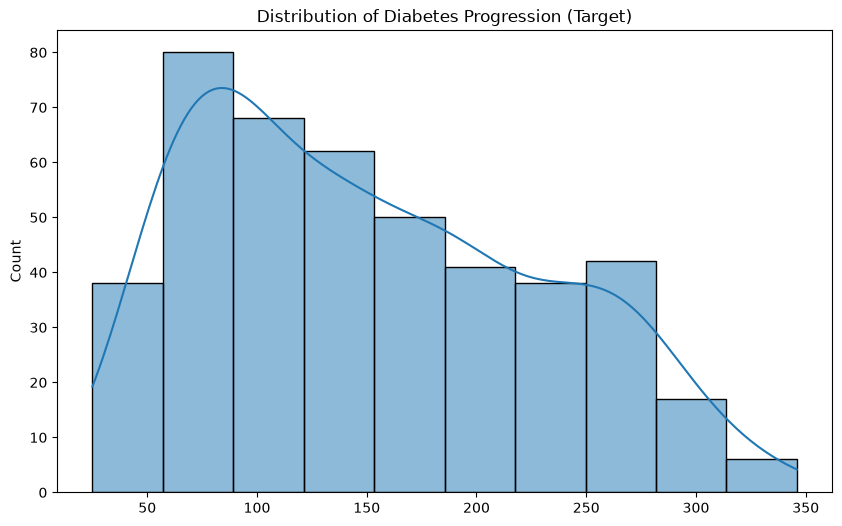

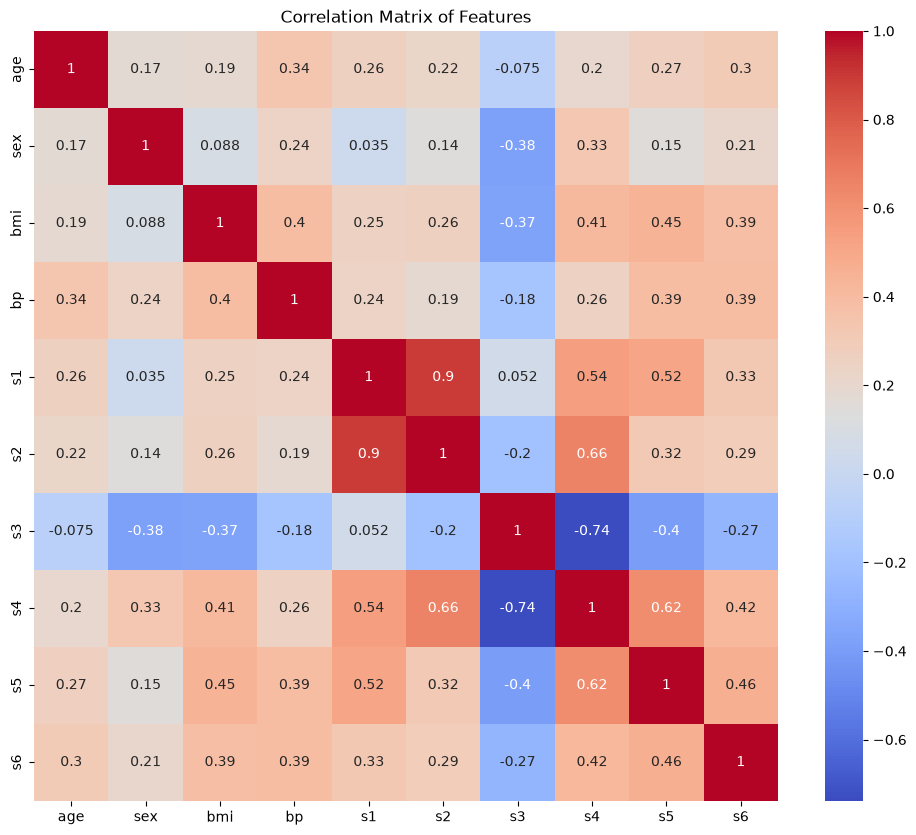

c:\Users\nikhi\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Base Model - MSE: 3435.20, R2 Score: 0.35


c:\Users\nikhi\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Improved Model - MSE: 3450.02, R2 Score: 0.35


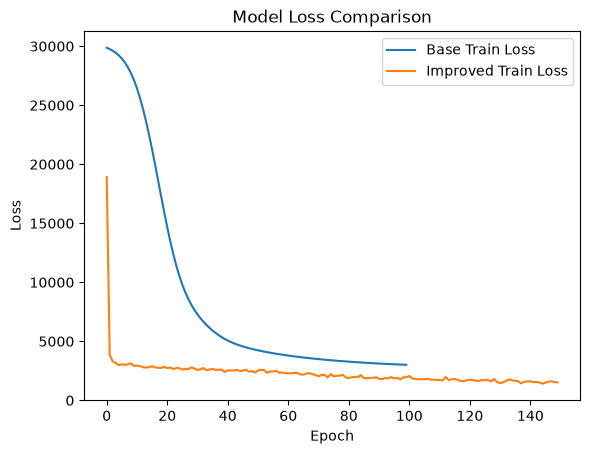

In [23]:
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title('Distribution of Diabetes Progression (Target)')
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Features')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

def build_base_model():
    model = Sequential([
        Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(8, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

base_model = build_base_model()
history = base_model.fit(X_train, y_train, validation_split=0.1, epochs=100, batch_size=16, verbose=0)

y_pred = base_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Base Model - MSE: {mse:.2f}, R2 Score: {r2:.2f}")

def build_improved_model():
    model = Sequential([
        Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
        Dropout(0.1),
        Dense(32, activation='relu'),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
    return model

improved_model = build_improved_model()
improved_history = improved_model.fit(X_train, y_train, validation_split=0.1, epochs=150, batch_size=8, verbose=0)

y_pred_improved = improved_model.predict(X_test)
mse_imp = mean_squared_error(y_test, y_pred_improved)
r2_imp = r2_score(y_test, y_pred_improved)

print(f"Improved Model - MSE: {mse_imp:.2f}, R2 Score: {r2_imp:.2f}")

plt.plot(history.history['loss'], label='Base Train Loss')
plt.plot(improved_history.history['loss'], label='Improved Train Loss')
plt.title('Model Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()